# Complexity-04d — Secretaire matroidal (C#)

**Navigation** : [README de la serie](README.md) · [version Python](Complexity-04d-Secretaire-Matroidal-Python.ipynb) · [04 — algorithmes en ligne](Complexity-04-OnlineAlgorithms-CSharp.ipynb) · [03c — carte du zoo](Complexity-03c-ComplexityZoo-Navigation-CSharp.ipynb)

Ce carnet est le **jumeau C#** du carnet Python homonyme. Meme algorithme, memes instances, memes
budgets ; implementations en bibliotheque standard .NET, sans aucun paquet externe. Les generateurs
pseudo-aleatoires de .NET et de NumPy ne produisent pas les memes suites : les instances simulees
different, donc les valeurs imprimees different de la version Python. Le **protocole** est identique.

Le sujet : l'algorithme de **Singla** pour le secretariat matroidal. Un oracle d'independance repond
« cet ensemble est-il independant ? » ; les elements arrivent dans un ordre aleatoire inconnu ; il
faut accepter un ensemble independant de valeur aussi grande que possible. La garantie du pire cas
est element-par-element : chaque element de l'optimum est accepte avec probabilite au moins **1/4**.

## Ce que le carnet mesure, et ce qu'il ne mesure pas

Trois mesures, et une distinction qui gouverne tout le reste :

- la **garantie element-par-element** — sur 4000 executions par instance, la frequence
  d'acceptation de chaque element de l'optimum. C'est une mesure, donc elle a un intervalle de
  confiance, et 4000 tirages donnent une erreur type de l'ordre de 0,008.
- le **ratio en esperance** — la valeur moyenne de l'ensemble accepte rapportee a la valeur de
  l'optimum. C'est la conduite quotidienne de l'algorithme, pas sa borne.
- la **comparaison avec le secretariat classique** — meme instance, seuil 1/e.

**Une frequence observee ne demontre pas une borne.** Le theoreme dit : pour toute instance, la
probabilite est au moins 1/4. La mesure dit : sur cette instance et ce generateur, la frequence
vaut telle valeur. La mesure peut *infirmer* la borne (une frequence nettement sous 1/4 serait un
contre-exemple, modulo le bruit d'echantillonnage) ; elle ne peut pas la confirmer.

In [1]:
// Outillage commun : bibliotheque standard .NET uniquement.
using System;
using System.Linq;
using System.Collections.Generic;
using System.Text;
using System.Globalization;
using System.Diagnostics;
using Microsoft.DotNet.Interactive.Formatting;

string BATCH_MODE = "true";
var Rng = new Random(20260925);

(double Min, T Valeur) Chrono<T>(Func<T> f, int repetitions = 3) {
    double best = double.MaxValue; T r = default;
    for (int i = 0; i < repetitions; i++) {
        var sw = Stopwatch.StartNew(); r = f(); sw.Stop();
        best = Math.Min(best, sw.Elapsed.TotalSeconds);
    }
    return (best, r);
}

// Affichage SVG natif : le MIME declare est image/svg+xml, pas text/html.
record SvgMarkup(string Content);
Formatter.Register<SvgMarkup>((v, ctx) => { ctx.Writer.Write(v.Content); return true; }, "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(SvgMarkup), new[] { "image/svg+xml" });
string F(double x) => x.ToString("0.##", CultureInfo.InvariantCulture);
string Esc(string s) => System.Security.SecurityElement.Escape(s) ?? "";
// Valeur affichee (axe, etiquettes) : virgule decimale. Les coordonnees SVG gardent le point.
string Fd(double x) => x.ToString("0.##", CultureInfo.GetCultureInfo("fr-FR"));

// Histogramme avec lignes de reference horizontales : la garantie se lit contre les barres.
string BarresSvg(string[] labels, double[] valeurs, (double Y, string Label, string Style)[] lignes,
                 string titre, string ylab) {
    const int W = 900, H = 400, L = 90, R = 40, Top = 55, Bot = 95;
    double yMax = Math.Max(0.6, valeurs.Max() + 0.05);
    double X(int i) => L + (W - L - R) * (i + 0.5) / labels.Length;
    double Y(double v) => H - Bot - v / yMax * (H - Top - Bot);
    double largeur = (W - L - R) / labels.Length * 0.55;
    var b = new StringBuilder();
    b.Append($"<svg xmlns='http://www.w3.org/2000/svg' width='{W}' height='{H}' viewBox='0 0 {W} {H}'>");
    b.Append("<rect width='100%' height='100%' fill='white'/>");
    b.Append($"<text x='{(L + W - R) / 2}' y='26' text-anchor='middle' font-family='sans-serif' font-size='14'>{Esc(titre)}</text>");
    b.Append($"<path d='M {L} {Top} V {H - Bot} H {W - R}' stroke='black' fill='none'/>");
    for (int k = 0; k <= 4; k++) {
        double v = yMax * k / 4.0;
        b.Append($"<text x='{L - 10}' y='{F(Y(v) + 4)}' text-anchor='end' font-family='sans-serif' font-size='11'>{Fd(v)}</text>");
        b.Append($"<path d='M {L} {F(Y(v))} H {W - R}' stroke='#e6e6e6' fill='none'/>");
    }
    for (int i = 0; i < labels.Length; i++) {
        double x = X(i) - largeur / 2, y = Y(valeurs[i]);
        b.Append($"<rect x='{F(x)}' y='{F(y)}' width='{F(largeur)}' height='{F(H - Bot - y)}' fill='#2455a4'/>");
        b.Append($"<text x='{F(X(i))}' y='{F(y - 6)}' text-anchor='middle' font-family='sans-serif' font-size='11'>{Fd(valeurs[i])}</text>");
        b.Append($"<text transform='translate({F(X(i))},{H - Bot + 14}) rotate(-35)' text-anchor='end' font-family='sans-serif' font-size='10'>{Esc(labels[i])}</text>");
    }
    double LargeurLegende(string s) => s.Length * 5.6 + 42;
    double xLegende = W - R - lignes.Sum(l => LargeurLegende(l.Label));
    foreach (var (y, lab, style) in lignes) {
        string dash = style == "trait" ? "" : " stroke-dasharray='7 5'";
        string couleur = style == "pointille" ? "#555555" : "#c33b31";
        b.Append($"<path d='M {L} {F(Y(y))} H {W - R}' stroke='{couleur}' stroke-width='2'{dash} fill='none'/>");
        // Legende en haut, sous le titre : les libelles poses sur la ligne entraient en collision
        // avec les valeurs des barres hautes (constate au rendu).
        b.Append($"<path d='M {F(xLegende)} 40 H {F(xLegende + 22)}' stroke='{couleur}' stroke-width='2'{dash} fill='none'/>");
        b.Append($"<text x='{F(xLegende + 28)}' y='44' font-family='sans-serif' font-size='11'>{Esc(lab)}</text>");
        xLegende += LargeurLegende(lab);
    }
    b.Append($"<text transform='translate(22,{(Top + H - Bot) / 2}) rotate(-90)' text-anchor='middle' font-family='sans-serif' font-size='12'>{Esc(ylab)}</text>");
    b.Append("</svg>");
    return b.ToString();
}

Console.WriteLine("Outillage en place : generateur a graine fixe, chronometre, rendu SVG opaque.");

Outillage en place : generateur a graine fixe, chronometre, rendu SVG opaque.


## 1. Trois oracles d'independance

Un matroide se presente par son **oracle d'independance** : une fonction qui, sur un ensemble
d'elements, repond oui ou non. Trois familles suffisent pour ce carnet :

- **uniforme de rang k** — independant si et seulement si la cardinalite ne depasse pas k ;
- **partition** — chaque element appartient a une classe, chaque classe a un plafond ;
- **graphique** — les elements sont des aretes d'un graphe, independant si et seulement si elles
  forment une foret (test par union-find).

L'instance temoin est la meme que dans la source : huit elements de poids distincts, trois classes,
huit aretes. Les poids sont volontairement non tries, pour que l'optimum ne se lise pas a l'oeil.

In [2]:
// --- 1. Les trois oracles d'independance ---
Func<IEnumerable<int>, bool> UniformOracle(int k) =>
    S => S.Count() <= k;

Func<IEnumerable<int>, bool> PartitionOracle(int[] classes, Dictionary<int, int> caps) =>
    S => {
        var cnt = new Dictionary<int, int>();
        foreach (int e in S) cnt[classes[e]] = cnt.GetValueOrDefault(classes[e], 0) + 1;
        return cnt.All(z => z.Value <= caps[z.Key]);
    };

Func<IEnumerable<int>, bool> GraphicOracle(int nbSommets, (int A, int B)[] aretes) =>
    S => {
        var parent = Enumerable.Range(0, nbSommets).ToArray();
        int Find(int x) { while (parent[x] != x) { parent[x] = parent[parent[x]]; x = parent[x]; } return x; }
        foreach (int e in S) {
            int ra = Find(aretes[e].A), rb = Find(aretes[e].B);
            if (ra == rb) return false;
            parent[ra] = rb;
        }
        return true;
    };

// L'instance temoin du carnet : 8 elements, poids fixes.
var Valeurs = new[] { 5.0, 1.0, 4.0, 3.0, 0.5, 2.0, 4.5, 0.2 };
var Classes = new[] { 0, 0, 0, 1, 1, 1, 2, 2 };
var Caps = new Dictionary<int, int> { [0] = 1, [1] = 2, [2] = 1 };
var Aretes = new[] { (0, 1), (0, 2), (1, 2), (1, 3), (2, 3), (2, 4), (3, 4), (0, 4) };

Console.WriteLine($"Instance temoin : n=8 elements, valeurs [{string.Join(", ", Valeurs)}]");
Console.WriteLine($"Uniforme rang 3 : accepter {{0, 2, 6}} ? {UniformOracle(3)(new[] { 0, 2, 6 })} ; {{0, 1, 2, 6}} ? {UniformOracle(3)(new[] { 0, 1, 2, 6 })}");
Console.WriteLine($"Partition : {{0, 1}} (deux de classe 0, cap 1) ? {PartitionOracle(Classes, Caps)(new[] { 0, 1 })} ; {{0, 3, 4}} ? {PartitionOracle(Classes, Caps)(new[] { 0, 3, 4 })}");
Console.WriteLine($"Graphique : {{0, 2, 7}} (triangle 0-1-2 + arete 0-4) ? {GraphicOracle(5, Aretes)(new[] { 0, 2, 7 })} ; {{0, 1, 5}} ? {GraphicOracle(5, Aretes)(new[] { 0, 1, 5 })}");

Instance temoin : n=8 elements, valeurs [5, 1, 4, 3, 0,5, 2, 4,5, 0,2]


Uniforme rang 3 : accepter {0, 2, 6} ? True ; {0, 1, 2, 6} ? False


Partition : {0, 1} (deux de classe 0, cap 1) ? False ; {0, 3, 4} ? True


Graphique : {0, 2, 7} (triangle 0-1-2 + arete 0-4) ? True ; {0, 1, 5} ? True


Chaque ligne de sortie est un controle de l'oracle, pas une illustration : les deux premiers cas
de chaque famille sont construits pour differer. Un oracle qui repondrait toujours oui passerait la
premiere moitie de chaque paire et echouerait la seconde.

## 2. L'optimum, et le glouton qui le trouve

Sur un matroide, le **glouton par poids decroissants** est optimal : il accepte un element si et
seulement si l'ensemble courant augmente de cet element reste independant. C'est une propriete des
matroides, pas une heuristique — et c'est ce qui donne un optimum calculable pour mesurer l'algorithme
en ligne contre lui.

In [3]:
// --- 2. Le glouton optimal sur un matroide ---
HashSet<int> Greedy(double[] poids, Func<IEnumerable<int>, bool> ind) {
    var b = new List<int>();
    foreach (int e in Enumerable.Range(0, poids.Length)
                               .Where(e => poids[e] > 0)
                               .OrderByDescending(e => poids[e])
                               .ThenBy(e => e)) {
        if (ind(b.Append(e))) b.Add(e);
    }
    return new HashSet<int>(b);
}

foreach (var (nom, ind) in new (string, Func<IEnumerable<int>, bool>)[] {
             ("uniforme k=3", UniformOracle(3)),
             ("partition", PartitionOracle(Classes, Caps)),
             ("graphique", GraphicOracle(5, Aretes)) }) {
    var opt = Greedy(Valeurs, ind);
    Console.WriteLine($"{nom,-13} OPT = [{string.Join(", ", opt.OrderBy(x => x))}] -> valeur {opt.Sum(e => Valeurs[e]):F1}");
}

uniforme k=3  OPT = [0, 2, 6] -> valeur 13,5


partition     OPT = [0, 3, 5, 6] -> valeur 14,5


graphique     OPT = [0, 2, 3, 6] -> valeur 16,5



warning CS1701: En supposant que la référence d'assembly 'Microsoft.AspNetCore.Html.Abstractions, Version=2.3.0.0, Culture=neutral, PublicKeyToken=adb9793829ddae60' utilisée par 'Microsoft.DotNet.Interactive.Formatting' correspond à l'identité 'Microsoft.AspNetCore.Html.Abstractions, Version=10.0.0.0, Culture=neutral, PublicKeyToken=adb9793829ddae60' de 'Microsoft.AspNetCore.Html.Abstractions', il se peut que vous deviez fournir une stratégie runtime



Les trois optima ne coincident pas : c'est la meme liste de poids vue par trois structures
d'independance differentes, et donc trois problemes distincts. Le carnet garde les trois, parce que
la garantie de l'algorithme en ligne doit tenir pour les trois.

## 3. L'algorithme en ligne

L'algorithme de Singla travaille sur un **ordre d'arrivee inconnu**. Il tire d'abord un entier K
selon une binomiale de parametres n et 1/2, met de cote K elements tires au hasard (l'« echantillon
exclus »), puis parcourt les elements dans un ordre virtuel ou les positions des elements mis de cote
sont elles-memes tirees au hasard.

A chaque element e, il construit une configuration candidate ou e prend son vrai poids, et compare
les bases gloutonnes des deux configurations **restreintes aux elements deja finalises**. Si rien ne
change sur cette partie deja figee, il peut decider : accepter e si la base candidate le contient.

In [4]:
// --- 3. Une execution de l'algorithme (RO 2-Sided GoG + reduction Bin(n, 1/2)) ---
HashSet<int> SinglaRun(double[] valeurs, Func<IEnumerable<int>, bool> ind, Random rng) {
    int n = valeurs.Length;
    var arrivee = Enumerable.Range(0, n).ToArray();
    // Fisher-Yates : ordre d'arrivee tire uniformement.
    for (int i = n - 1; i > 0; i--) { int j = rng.Next(i + 1); (arrivee[i], arrivee[j]) = (arrivee[j], arrivee[i]); }
    int K = Enumerable.Range(0, n).Count(_ => rng.NextDouble() < 0.5);   // K ~ Bin(n, 1/2)
    var kal = new HashSet<int>(arrivee.Take(K));                          // echantillon : mis de cote
    var W = Enumerable.Range(0, n).Select(e => kal.Contains(e) ? valeurs[e] : 0.0).ToArray();
    // Ordre virtuel : K positions marquees AU HASARD portent les elements mis de cote.
    var positions = new HashSet<int>();
    while (positions.Count < K) positions.Add(rng.Next(n));
    var virtuel = new int[n];
    int ik = 0, ir = K;
    for (int p = 0; p < n; p++) virtuel[p] = positions.Contains(p) ? arrivee[ik++] : arrivee[ir++];

    var acceptes = new HashSet<int>();
    var finalises = new HashSet<int>();
    foreach (int e in virtuel) {
        var wp = (double[])W.Clone();
        wp[e] = kal.Contains(e) ? 0.0 : valeurs[e];
        var gBase = Greedy(W, ind);
        var gProp = Greedy(wp, ind);
        bool memesSurLeFige = gBase.Intersect(finalises).OrderBy(x => x)
                                  .SequenceEqual(gProp.Intersect(finalises).OrderBy(x => x));
        if (memesSurLeFige) {
            if (gProp.Contains(e)) acceptes.Add(e);
            W = wp;
        }
        finalises.Add(e);
    }
    acceptes.ExceptWith(kal);
    return acceptes;
}

var rngDemo = new Random(1);
var algDemo = SinglaRun(Valeurs, UniformOracle(3), rngDemo);
Console.WriteLine($"Une execution (uniforme k=3) : ALG = [{string.Join(", ", algDemo.OrderBy(x => x))}], "
                + $"valeur {algDemo.Sum(e => Valeurs[e]):F1} (OPT = {Greedy(Valeurs, UniformOracle(3)).Sum(e => Valeurs[e]):F1})");

Une execution (uniforme k=3) : ALG = [2, 3], valeur 7,0 (OPT = 13,5)


La comparaison sur la partie **deja figee** est le coeur de l'algorithme : elle garantit que la
decision prise maintenant ne pourra plus etre remise en cause par un element ulterieur. C'est ce qui
autorise une decision en ligne sans connaitre la suite, et c'est aussi ce qui coute : l'algorithme
refuse parfois un element qu'un oracle omniscient aurait pris.

Une execution unique ne dit rien de la garantie. Il faut repeter, et compter par element.

## 4. La garantie element-par-element, mesuree

Protocole : pour chaque instance, 4000 executions. Pour chaque element de l'optimum, on compte les
executions ou il a ete accepte. La plus petite de ces frequences **est** le minimum mesure — la
quantite que le theoreme minore par 1/4.

In [5]:
// --- 4. Banc de garantie : 4000 executions par instance ---
(HashSet<int> Opt, Dictionary<int, double> Freq, double ValeurMoyenne) BancGarantie(
        double[] valeurs, Func<IEnumerable<int>, bool> ind, int essais = 4000, int graine = 7) {
    var rng = new Random(graine);
    var opt = Greedy(valeurs, ind);
    var freq = opt.ToDictionary(e => e, e => 0);
    double valeurMoyenne = 0.0;
    for (int t = 0; t < essais; t++) {
        var alg = SinglaRun(valeurs, ind, rng);
        foreach (int e in opt) if (alg.Contains(e)) freq[e]++;
        valeurMoyenne += alg.Sum(e => valeurs[e]);
    }
    return (opt, freq.ToDictionary(z => z.Key, z => (double)z.Value / essais), valeurMoyenne / essais);
}

var instances = new (string Nom, Func<IEnumerable<int>, bool> Ind)[] {
    ("uniforme k=1", UniformOracle(1)),
    ("uniforme k=2", UniformOracle(2)),
    ("uniforme k=3", UniformOracle(3)),
    ("uniforme k=4", UniformOracle(4)),
    ("partition", PartitionOracle(Classes, Caps)),
    ("graphique", GraphicOracle(5, Aretes)),
};

var resultats = new Dictionary<string, (HashSet<int> Opt, Dictionary<int, double> Freq, double ValeurMoyenne)>();
Console.WriteLine($"{"instance",-14} {"valeur OPT",10} {"min P[accept]",13} {"E[ALG]/OPT",10}   frequences par element de OPT");
foreach (var (nom, ind) in instances) {
    var (opt, freqs, valMoy) = BancGarantie(Valeurs, ind);
    resultats[nom] = (opt, freqs, valMoy);
    double vOpt = opt.Sum(e => Valeurs[e]);
    string detail = string.Join(" ", opt.OrderBy(x => x).Select(e => freqs[e].ToString("F2", CultureInfo.InvariantCulture)));
    Console.WriteLine($"{nom,-14} {vOpt,10:F1} {freqs.Values.Min(),13:F3} {valMoy / vOpt,10:F2}   {detail}");
}

instance       valeur OPT min P[accept] E[ALG]/OPT   frequences par element de OPT


uniforme k=1          5,0         0,253       0,45   0.25


uniforme k=2          9,5         0,274       0,43   0.27 0.28


uniforme k=3         13,5         0,296       0,43   0.32 0.30 0.32


uniforme k=4         16,5         0,364       0,45   0.39 0.36 0.38 0.39


partition            14,5         0,326       0,45   0.33 0.44 0.44 0.38


graphique            16,5         0,351       0,45   0.40 0.35 0.38 0.40


Deux colonnes se lisent ensemble. La frequence minimale est la quantite que le theoreme minore ;
le ratio en esperance est la conduite de l'algorithme sur cette instance. Les deux repondent a des
questions differentes, et confondre l'une avec l'autre est l'erreur que la figure suivante rend
visible.

La figure place les deux bornes de reference sur le meme axe que les barres : 1/4, la garantie du
theoreme, et 1/e, l'optimum du secretariat classique au rang 1. Une instance dont la barre passerait
sous 1/4 avec 4000 tirages serait un contre-exemple mesure — pas une curiosite.

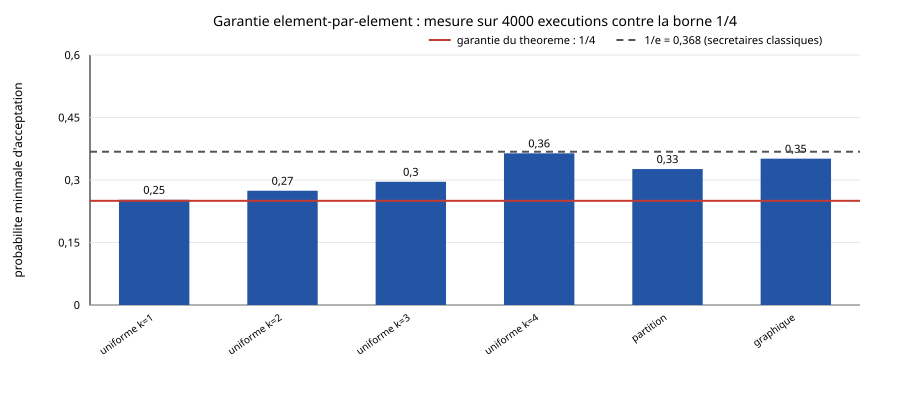

Figure : barres mesurees, deux lignes de reference, fond blanc opaque.


In [6]:
// Figure : minimum mesure par instance, contre les deux bornes de reference.
var noms = instances.Select(z => z.Nom).ToArray();
var minima = noms.Select(n => resultats[n].Freq.Values.Min()).ToArray();
var figGarantie = BarresSvg(noms, minima, new (double, string, string)[] {
        (0.25, "garantie du theoreme : 1/4", "trait"),
        (1.0 / 2.71828, "1/e = 0,368 (secretaires classiques)", "pointille")
    },
    "Garantie element-par-element : mesure sur 4000 executions contre la borne 1/4",
    "probabilite minimale d'acceptation");
display(new SvgMarkup(figGarantie));
Console.WriteLine("Figure : barres mesurees, deux lignes de reference, fond blanc opaque.");

La lecture utile est un **ecart a la borne**, pas un classement des instances. Toutes les barres
doivent rester au-dessus de 1/4 : si l'une passait dessous, ce serait un contre-exemple mesure au
theoreme, et il faudrait d'abord soupconner l'implementation avant de soupconner le theoreme.

L'ecart entre les barres et la ligne 1/e est instructif pour une autre raison : sur certaines
instances l'algorithme matroidal depasse le secretariat classique, ce qui est attendu — il utilise
davantage d'information (l'oracle d'independance) que le simple rang du meilleur element vu.

## 5. Le ratio en esperance : la conduite quotidienne

La garantie element-par-element implique, par linearite de l'esperance, que la valeur moyenne de
l'ensemble accepte est au moins le quart de l'optimum. Le **ratio mesure** est generalement bien
au-dessus : la garantie est un plancher de pire cas, pas une prevision.

In [7]:
// --- 5. Ratio E[ALG]/OPT, instance par instance ---
Console.WriteLine($"{"instance",-14} {"E[ALG]/OPT",10} {"garantie",9}");
foreach (var nom in noms) {
    var (opt, _, valMoy) = resultats[nom];
    double vOpt = opt.Sum(e => Valeurs[e]);
    Console.WriteLine($"{nom,-14} {valMoy / vOpt,10:F3} {0.25,9:F3}");
}
double sommeRatios = 0;
foreach (var nom in noms) sommeRatios += resultats[nom].ValeurMoyenne / resultats[nom].Opt.Sum(e => Valeurs[e]);
double moyenneRatios = sommeRatios / noms.Length;
Console.WriteLine($"Moyenne des {noms.Length} ratios : {moyenneRatios:F3}");

instance       E[ALG]/OPT  garantie


uniforme k=1        0,454     0,250


uniforme k=2        0,427     0,250


uniforme k=3        0,425     0,250


uniforme k=4        0,455     0,250


partition           0,455     0,250


graphique           0,452     0,250


Moyenne des 6 ratios : 0,445


Le ratio moyen se lit comme un **facteur** : un ratio de 0,44 signifie que l'algorithme capture un
peu moins de la moitie de la valeur optimale sur ces instances. Le meme motif que pour l'algorithme
du secretariat dans le carnet 04 : la borne du pire cas et la conduite quotidienne ne sont pas la
meme quantite, et presenter la premiere comme une prediction de la seconde est l'erreur a eviter.

## 6. Comparaison avec le secretariat classique

Le secretariat classique observe une fraction n/e des candidats, retient la meilleure valeur vue,
puis accepte le premier candidat qui la depasse. Sa garantie asymptotique est 1/e, et sa valeur
exacte pour n donne se calcule par une somme finie — mais ici on la **mesure**, sur la meme instance.

Le point de la comparaison n'est pas de designer un gagnant : les deux algorithmes ne resolvent pas
le meme probleme (l'un accepte un element, l'autre un ensemble independant). Le point est de montrer
que la meme instance, mesuree deux fois, donne deux frequences qu'on ne peut pas comparer sans dire
ce qu'elles mesurent.

In [8]:
// --- 6. Secretariat classique (seuil n/e) sur la meme instance, 4000 tirages ---
int SecretairesClassique(double[] valeurs, Random rng) {
    int n = valeurs.Length;
    int nObs = Math.Max(1, (int)Math.Round(n / 2.71828));
    var ordre = Enumerable.Range(0, n).ToArray();
    for (int i = n - 1; i > 0; i--) { int j = rng.Next(i + 1); (ordre[i], ordre[j]) = (ordre[j], ordre[i]); }
    double seuil = ordre.Take(nObs).Max(e => valeurs[e]);
    foreach (int e in ordre.Skip(nObs)) if (valeurs[e] > seuil) return e;
    return -1;
}

var rngCmp = new Random(11);
const int T = 4000;
int succesClassique = 0;
int indiceMeilleur = Array.IndexOf(Valeurs, Valeurs.Max());
for (int t = 0; t < T; t++) if (SecretairesClassique(Valeurs, rngCmp) == indiceMeilleur) succesClassique++;
Console.WriteLine($"Secretaire classique (seuil n/e), rang 1, n=8 : P[recruter le meilleur] = {(double)succesClassique / T:F3}");
Console.WriteLine($"  [limite asymptotique 1/e = {1 / 2.71828:F3}]");
Console.WriteLine($"Algorithme de Singla, meme instance           : P[accepter le meilleur] = {resultats["uniforme k=1"].Freq[indiceMeilleur]:F3}");
Console.WriteLine($"  [garantie 1/4 = 0,250]");

Secretaire classique (seuil n/e), rang 1, n=8 : P[recruter le meilleur] = 0,415


  [limite asymptotique 1/e = 0,368]


Algorithme de Singla, meme instance           : P[accepter le meilleur] = 0,253


  [garantie 1/4 = 0,250]


Les deux frequences portent sur le **meme** element, mais pas sur le meme evenement : le
secretariat classique « recrute » un seul candidat et reussit s'il tombe sur le meilleur ; l'algorithme
matroidal accepte un ensemble et reussit si le meilleur element est dedans. Comparer les deux nombres
comme s'ils mesuraient la meme chose serait une faute de lecture, et c'est une faute courante.

Un second point, plus important pour la suite : la valeur 1/e est une **limite asymptotique**, alors
que la frequence mesuree est celle d'un n fini. Sur huit candidats, les deux different ; l'ecart n'est
pas une erreur, c'est la difference entre une limite et une valeur.

## 7. Exercices

Trois exercices, chacun avec une **garde** : une fonction qui accepte une proposition et la confronte
a des fixtures. La garde est elle-meme controlee dans la cellule par des **mutants** qu'elle doit
refuser. Tant que l'exercice n'est pas complete, la garde s'arrete sur `null` et l'imprime.

### Exercice 1 — mesurer une intersection jointe, pas un produit de marginales

C'est l'exercice corrige de ce carnet, et sa formulation d'origine etait fautive.

La faute : pour la probabilite que **deux** elements de l'optimum soient acceptes, on pourrait etre
tente de multiplier leurs frequences d'acceptation individuelles. Ce produit n'est la probabilite
jointe que si les deux evenements sont **independants**. Ici ils ne le sont pas : les deux elements
appartiennent au meme ensemble independant, et accepter l'un consomme de la capacite qui manquera a
l'autre. Le produit surestime donc la probabilite jointe des que la dependance est negative, et rien
ne garantit son signe.

La correction : mesurer l'intersection **directement sur l'echantillon**. Completer
`JointDepuisEchantillon` : `observations[t][e]` dit si l'element `e` a ete accepte au tirage `t` ;
il faut rendre la proportion de tirages ou **tous** les elements de `cible` sont acceptes ensemble.

La garde utilise un echantillon construit a la main, ou le produit des marginales et l'intersection
jointe different : les deux evenements y sont negativement correles.

In [9]:
// Exercice 1 : a completer
double? JointDepuisEchantillon(bool[][] observations, int[] cible) {
    // TODO etudiant : proportion de tirages ou TOUS les elements de `cible` sont acceptes
    // dans le MEME tirage. Ne pas multiplier les frequences marginales : les acceptations
    // sont correlees, le produit n'est pas l'intersection.
    return null;   // TODO etudiant
}
// Indice : parcourir les tirages, pas les elements.

// --- Garde de l'exercice 1 : echantillon construit a la main ---
// 10 tirages, cible {0, 2} : 2 fois les deux, 3 fois le premier seul, 3 fois le second seul,
// 2 fois aucun. Marginale de chacun : 5/10 = 0,5 ; produit : 0,25 ; intersection jointe : 0,20.
var FixtureObs1 = new bool[10][];
for (int t = 0; t < 10; t++) FixtureObs1[t] = new bool[3];
for (int t = 0; t < 2; t++) { FixtureObs1[t][0] = true; FixtureObs1[t][2] = true; }
for (int t = 2; t < 5; t++) FixtureObs1[t][0] = true;
for (int t = 5; t < 8; t++) FixtureObs1[t][2] = true;

string Garde1(Func<bool[][], int[], double?> candidat) {
    var essais = new (string Nom, int[] Cible, double Attendu)[] {
        ("paire negativement correlee", new[] { 0, 2 }, 0.20),
        ("element seul",                new[] { 0 },    0.50),
        ("element jamais accepte",      new[] { 1 },    0.00),
    };
    foreach (var (nom, cible, attendu) in essais) {
        double? r;
        try { r = candidat(FixtureObs1, cible); }
        catch (Exception e) { return $"ECHEC {nom} : exception {e.GetType().Name}"; }
        if (r is null) return $"NON IMPLEMENTE : la garde s'arrete sur null ({nom})";
        if (Math.Abs(r.Value - attendu) > 1e-9) return $"ECHEC {nom} : attendu {attendu:F3}, obtenu {r.Value:F3}";
    }
    return "OK";
}

// Controle de la garde : trois mutants qu'elle doit refuser, un oracle de fixtures qu'elle accepte.
double? MutantProduit1(bool[][] obs, int[] cible) {
    double p = 1.0;
    foreach (int e in cible) {
        int c = obs.Count(o => o[e]);
        p *= (double)c / obs.Length;
    }
    return p;
}
double? MutantAuMoinsUn1(bool[][] obs, int[] cible) =>
    (double)obs.Count(o => cible.Any(e => o[e])) / obs.Length;
double? MutantConstante1(bool[][] obs, int[] cible) => 1.0;
double? OracleFixtures1(bool[][] obs, int[] cible) =>
    (double)obs.Count(o => cible.All(e => o[e])) / obs.Length;

Console.WriteLine($"Garde sur la reponse de l'etudiant      : {Garde1(JointDepuisEchantillon)}");
Console.WriteLine($"Garde sur le mutant produit             : {Garde1(MutantProduit1)}");
Console.WriteLine($"Garde sur le mutant au moins un         : {Garde1(MutantAuMoinsUn1)}");
Console.WriteLine($"Garde sur le mutant constant            : {Garde1(MutantConstante1)}");
Console.WriteLine($"Garde sur l'oracle de fixtures          : {Garde1(OracleFixtures1)}");

Garde sur la reponse de l'etudiant      : NON IMPLEMENTE : la garde s'arrete sur null (paire negativement correlee)


Garde sur le mutant produit             : ECHEC paire negativement correlee : attendu 0,200, obtenu 0,250


Garde sur le mutant au moins un         : ECHEC paire negativement correlee : attendu 0,200, obtenu 0,800


Garde sur le mutant constant            : ECHEC paire negativement correlee : attendu 0,200, obtenu 1,000


Garde sur l'oracle de fixtures          : OK


Le mutant par produit est le plus interessant : il rend la bonne valeur pour un element seul —
parce que le produit d'un seul facteur est bien la marginale — et se trompe des qu'il y en a deux.
C'est exactement le raisonnement fautif que la formulation d'origine invitait a faire, et la garde le
refuse explicitement.

Le carnet imprime ensuite, sur le vrai banc, l'intersection jointe et le produit des marginales cote
a cote : le lecteur voit l'ecart mesure, et non un argument general.

In [10]:
// Application au vrai banc : joint mesure contre produit des marginales, sur les quotas de classe 0.
Console.WriteLine($"{"quota",6} {"elements OPT",14} {"joint",7} {"produit",8} {"ecart",7}");
foreach (int quota in new[] { 1, 2, 3 }) {
    var caps = new Dictionary<int, int> { [0] = quota, [1] = 2, [2] = 1 };
    var ind = PartitionOracle(Classes, caps);
    var opt = Greedy(Valeurs, ind);
    var c0 = opt.Where(e => Classes[e] == 0).OrderBy(x => x).ToArray();
    var rng = new Random(7);
    var compte = new Dictionary<int, int>();
    foreach (int e in c0) compte[e] = 0;
    int joint = 0;
    const int essais = 4000;
    for (int t = 0; t < essais; t++) {
        var alg = SinglaRun(Valeurs, ind, rng);
        if (c0.All(e => alg.Contains(e))) joint++;
        foreach (int e in c0) if (alg.Contains(e)) compte[e]++;
    }
    double pJoint = (double)joint / essais;
    double produit = c0.Aggregate(1.0, (acc, e) => acc * compte[e] / essais);
    Console.WriteLine($"{quota,6} [{string.Join(", ", c0)}]{new string(' ', Math.Max(0, 12 - string.Join(", ", c0).Length))} "
                    + $"{pJoint,7:F3} {produit,8:F3} {produit - pJoint,7:F3}");
}

 quota   elements OPT   joint  produit   ecart


     1 [0]              0,326    0,326   0,000


     2 [0, 2]           0,166    0,192   0,026


     3 [0, 1, 2]        0,119    0,122   0,003


Cette table est la lecon de l'exercice, et elle est plus fine que « le produit est faux ». Sur
cette instance temoin, l'ecart mesure est **petit** : les deux quantites sont proches. Cela ne
justifie pas le produit — cela montre qu'une coincidence mesuree sur une instance ne se transporte
pas en regle. Le signe et l'amplitude de l'ecart dependent de l'instance et de la structure
d'independance ; seul le comptage direct est juste dans tous les cas.

C'est aussi pourquoi la garde de l'exercice n'a pas ete construite sur cet ecart : un controle fonde
sur une difference trop faible laisserait passer le mutant. La garde utilise un echantillon ou la
correlation est franche.

### Exercice 2 — construire une instance ou le minimum mesure est plus bas

La garantie est un plancher : 1/4. Où ce plancher est-il le plus proche d'etre atteint ? Completer
`InstancePresqueUnQuart` en rendant une instance (poids et oracle) dont le minimum mesure est
**strictement plus bas** que celui de l'instance temoin, sans jamais passer sous 1/4.

La garde mesure d'abord l'instance temoin comme reference, puis l'instance proposee, et exige une
baisse **stricte**, a graine et a nombre de tirages identiques : c'est la seule comparaison qui ne
depende pas d'un seuil choisi a la main. La reference est recalculee a l'execution, pas figee dans le
code, donc la garde reste valide si le generateur change.

In [11]:
// Exercice 2 : a completer
// Une instance est un couple (poids, oracle d'independance). Le type nomme evite une signature
// de tuple nullable, illisible a l'ecran et ambigue pour le compilateur en position de retour.
record InstanceMatroidale(double[] Valeurs, Func<IEnumerable<int>, bool> Ind);

InstanceMatroidale InstancePresqueUnQuart() {
    // TODO etudiant : construire (poids, oracle) dont le minimum mesure de P[accept | e dans OPT]
    // est strictement plus bas que sur l'instance temoin, tout en restant au-dessus de 1/4.
    return null;   // TODO etudiant
}
// Indice : l'optimum doit contenir plusieurs elements en concurrence pour la meme capacite.

// --- Garde de l'exercice 2 ---
string Garde2(Func<InstanceMatroidale> candidat) {
    double temoinMin = BancGarantie(Valeurs, PartitionOracle(Classes, Caps), 1000, 424242)
        .Freq.Values.Min();
    InstanceMatroidale propose;
    try { propose = candidat(); }
    catch (Exception e) { return $"ECHEC exception {e.GetType().Name}"; }
    if (propose is null) return "NON IMPLEMENTE : la garde s'arrete sur null";
    if (propose.Valeurs is null || propose.Valeurs.Length < 2) return "ECHEC instance vide ou trop petite";
    if (propose.Ind is null) return "ECHEC oracle absent";
    var opt = Greedy(propose.Valeurs, propose.Ind);
    double vOpt = opt.Sum(e => propose.Valeurs[e]);
    if (opt.Count == 0 || vOpt <= 0) return "ECHEC l'optimum propose est vide ou de valeur nulle";
    var (_, freq, _) = BancGarantie(propose.Valeurs, propose.Ind, 1000, 424242);
    double min = freq.Values.Min();
    if (min < 0.25) return $"ECHEC minimum {min:F3} sous la garantie 1/4";
    if (min >= temoinMin - 1e-9) return $"ECHEC minimum {min:F3} non strictement inferieur a la reference {temoinMin:F3}";
    return $"OK (temoin {temoinMin:F3}, propose {min:F3})";
}

// Controle de la garde : mutant qui rend l'instance temoin, mutant dont l'optimum est vide.
InstanceMatroidale MutantTemoin2() => new(Valeurs, PartitionOracle(Classes, Caps));
InstanceMatroidale MutantOptimumVide2() => new(new[] { 0.0, 0.0, 0.0 }, UniformOracle(1));
// Oracle de fixtures : concentre le poids sur les elements de meme classe, ou la capacite se dispute.
InstanceMatroidale OracleFixtures2() =>
    new(new[] { 5.0, 4.9, 4.8, 4.7, 4.6, 4.5, 4.4, 4.3 }, UniformOracle(3));

Console.WriteLine($"Garde sur la reponse de l'etudiant      : {Garde2(InstancePresqueUnQuart)}");
Console.WriteLine($"Garde sur le mutant instance temoin     : {Garde2(MutantTemoin2)}");
Console.WriteLine($"Garde sur le mutant optimum vide        : {Garde2(MutantOptimumVide2)}");
Console.WriteLine($"Garde sur l'oracle de fixtures          : {Garde2(OracleFixtures2)}");

Garde sur la reponse de l'etudiant      : NON IMPLEMENTE : la garde s'arrete sur null


Garde sur le mutant instance temoin     : ECHEC minimum 0,332 non strictement inferieur a la reference 0,332


Garde sur le mutant optimum vide        : ECHEC l'optimum propose est vide ou de valeur nulle


Garde sur l'oracle de fixtures          : OK (temoin 0,332, propose 0,298)


La baisse attendue est faible, et c'est le sujet : le plancher 1/4 n'est pas atteint par les
instances naturelles de ce carnet. Chercher une instance qui s'en approche est un exercice de
construction, pas de parametrage — et la garde exige que l'optimum reste non trivial, sinon
n'importe quelle instance vide satisferait la contrainte.

### Exercice 3 — le secretariat au rang 2

Le secretariat classique accepte **un** element. Sa generalisation au rang k accepte un ensemble de
k elements : observer une fraction des candidats, puis accepter les k suivants qui battent le seuil
observe, avec une politique de rattrapage quand l'ordre se termine trop tot.

Completer `SecretairesK2` : rendre un ensemble d'au plus deux elements, avec `rattrapage` valant
`"dernier"` (prendre les derniers vus) ou `"deux_derniers"`.

La garde verifie trois proprietes : la taille ne depasse pas deux, tous les elements rendus sont
valides, et la sortie **varie** d'une execution a l'autre — une fonction qui rendrait les deux
meilleurs elements de la liste entiere serait un oracle hors ligne, pas un algorithme en ligne.

In [12]:
// Exercice 3 : a completer
HashSet<int> SecretairesK2(double[] valeurs, Random rng, string rattrapage = "dernier") {
    // TODO etudiant : seuil 1/e generalise au rang 2 ; rendre au plus deux elements.
    // rattrapage : politique quand moins de deux candidats battent le seuil.
    return null;   // TODO etudiant
}
// Indice : la sortie doit dependre de l'ordre d'arrivee tire, donc du generateur recu.

// --- Garde de l'exercice 3 ---
string Garde3(Func<double[], Random, string, HashSet<int>> candidat) {
    const int essais = 200;
    var rendus = new List<HashSet<int>>();
    for (int t = 0; t < essais; t++) {
        HashSet<int> r;
        try { r = candidat(Valeurs, new Random(9000 + t), "dernier"); }
        catch (Exception e) { return $"ECHEC exception {e.GetType().Name}"; }
        if (r is null) return "NON IMPLEMENTE : la garde s'arrete sur null";
        if (r.Count > 2) return $"ECHEC taille {r.Count} > 2";
        if (r.Any(e => e < 0 || e >= Valeurs.Length)) return "ECHEC element hors bornes";
        rendus.Add(r);
    }
    if (rendus.All(r => r.Count == 0)) return "ECHEC ensemble vide a chaque execution";
    int distincts = rendus.Select(r => string.Join(",", r.OrderBy(x => x))).Distinct().Count();
    if (distincts < 2) return "ECHEC sortie deterministe : un algorithme en ligne depend de l'ordre d'arrivee";
    var top2 = Enumerable.Range(0, Valeurs.Length).OrderByDescending(e => Valeurs[e]).Take(2).ToHashSet();
    double capture = rendus.Average(r => (double)r.Intersect(top2).Count() / 2);
    // Un tirage au hasard de deux elements capturerait 2/8 = 0,25 en moyenne : le plancher 0,30
    // separe un algorithme de rang 2 d'un tirage sans information.
    if (capture < 0.30) return $"ECHEC capture moyenne {capture:F2} trop faible pour un rang 2";
    return $"OK (capture moyenne {capture:F2}, {distincts} sorties distinctes)";
}

// Controle de la garde : deux mutants qu'elle doit refuser, un oracle de fixtures qu'elle accepte.
HashSet<int> MutantHorsLigne3(double[] v, Random rng, string rap) =>
    Enumerable.Range(0, v.Length).OrderByDescending(e => v[e]).Take(2).ToHashSet();
HashSet<int> MutantVide3(double[] v, Random rng, string rap) => new HashSet<int>();
HashSet<int> MutantTrois3(double[] v, Random rng, string rap) => new HashSet<int> { 0, 2, 6 };
// Oracle de fixtures : observe la moitie des arrivees, puis accepte les deux premiers qui battent
// le seuil observe ; a defaut, la politique de rattrapage s'applique.
HashSet<int> OracleFixtures3(double[] v, Random rng, string rap) {
    int n = v.Length;
    int nObs = Math.Max(1, n / 2);
    var ordre = Enumerable.Range(0, n).ToArray();
    for (int i = n - 1; i > 0; i--) { int j = rng.Next(i + 1); (ordre[i], ordre[j]) = (ordre[j], ordre[i]); }
    double seuil = ordre.Take(nObs).Max(e => v[e]);
    var pris = ordre.Skip(nObs).Where(e => v[e] > seuil).Take(2).ToHashSet();
    if (pris.Count < 2) {
        var reste = ordre.Skip(nObs).Where(e => !pris.Contains(e)).ToList();
        int manque = 2 - pris.Count;
        IEnumerable<int> secours = rap == "deux_derniers" ? reste.TakeLast(manque) : reste.TakeLast(1);
        foreach (int e in secours) pris.Add(e);
    }
    return pris;
}

Console.WriteLine($"Garde sur la reponse de l'etudiant      : {Garde3(SecretairesK2)}");
Console.WriteLine($"Garde sur le mutant hors ligne          : {Garde3(MutantHorsLigne3)}");
Console.WriteLine($"Garde sur le mutant vide                : {Garde3(MutantVide3)}");
Console.WriteLine($"Garde sur le mutant a trois elements    : {Garde3(MutantTrois3)}");
Console.WriteLine($"Garde sur l'oracle de fixtures          : {Garde3(OracleFixtures3)}");

Garde sur la reponse de l'etudiant      : NON IMPLEMENTE : la garde s'arrete sur null


Garde sur le mutant hors ligne          : ECHEC sortie deterministe : un algorithme en ligne depend de l'ordre d'arrivee


Garde sur le mutant vide                : ECHEC ensemble vide a chaque execution


Garde sur le mutant a trois elements    : ECHEC taille 3 > 2


Garde sur l'oracle de fixtures          : OK (capture moyenne 0,38, 17 sorties distinctes)


Le mutant hors ligne est celui qui compte : il **reussit** toutes les mesures de qualite — il rend
toujours les deux meilleurs elements — et il est pourtant faux, parce qu'il lit toute la liste. La
propriete qui l'attrape est la variabilite : un algorithme en ligne ne peut pas rendre la meme reponse
a chaque ordre d'arrivee. Une garde qui ne mesurerait que la qualite le laisserait passer.

## 8. Ce que ce carnet ne prouve pas

Quatre limites, ecrites pour qu'elles ne soient pas lues entre les lignes.

1. **Une frequence mesuree n'est pas une borne demontree.** 4000 tirages donnent une erreur type de
   l'ordre de 0,008 sur une probabilite proche de 1/4. La mesure peut infirmer la garantie ; elle ne
   peut pas la confirmer.
2. **Le produit de marginales n'est pas l'intersection jointe.** La table de la section 7 montre un
   ecart mesure faible sur l'instance temoin : c'est une coincidence d'instance, pas une regle. Seul
   le comptage direct est correct dans tous les cas.
3. **Les instances sont petites.** Huit elements, trois classes, huit aretes : assez pour que
   l'optimum soit calculable exactement, pas assez pour dire quoi que ce soit d'asymptotique.
4. **Les deux algorithmes ne resolvent pas le meme probleme.** Comparer la frequence du secretariat
   classique a celle de l'algorithme matroidal demande de dire ce que chacune mesure ; sans cela, la
   comparaison est un nombre sans contenu.

**Suite** : [03c — carte du zoo](Complexity-03c-ComplexityZoo-Navigation-CSharp.ipynb) applique la
meme discipline a la carte P / NP, et separe de la meme facon ce qui est mesure, ce qui est cite et
ce qui est ouvert.

## A retenir

- Le **secretaire matroidal** applique un algorithme en ligne (reduction Bin(n, 1/2)) a trois structures d'independance : uniforme, partition, graphique -- sur la **meme** liste de poids.
- Les trois oracles d'independance produisent **trois optima distincts** pour les memes poids : uniforme k=3 -> 13,5 ; partition -> 14,5 ; graphique -> 16,5. La structure change le probleme, pas les poids.
- Sur le banc de 4000 executions par instance, le ratio mesure **E[ALG]/OPT ~ 0,445**, nettement au-dessus de la garantie theorique **1/4 = 0,250**.
- Face a face sur la meme instance : le seuil classique n/e recrute le meilleur avec P ~ 0,415 (limite 1/e = 0,368) ; l'algorithme de Singla avec P ~ 0,253 (garantie 1/4).

## Verifiez votre comprehension

- Pourquoi trois oracles d'independance produisent-ils des **optima distincts** alors que les poids sont identiques ?
- Que mesure le ratio E[ALG]/OPT, et pourquoi le lire comme un **facteur au-dessus de la borne 1/4** plutot que comme un classement des instances ?
- Le secretaire classique (seuil n/e) et l'algorithme de Singla ciblent-ils le **meme evenement** ? (indice : meme element, evenement different -- relire la cellule de confrontation.)

## Pour aller plus loin

- Le probleme du **secretaire classique** et le seuil 1/e (fraction n/e des premiers candidats).
- L'algorithme de **Singla** pour le probleme du secretaire et sa garantie 1/4.
- Les **matroides** (uniforme, partition, graphique) et l'optimalite de l'algorithme glouton sur un matroide.
- Les algorithmes en ligne et les **reductions par bornes** (2-Sided GoG).